[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/24_contrastive_learning.ipynb)

# 24 · Contrastive Learning: Representations From Unlabeled Data

**Part 4 — Deep generative & representation learning** · Notebook 24 of 27

Labels are expensive; raw data is cheap. A hospital has millions of scans but only thousands with expert annotations. The web has billions of images, most without captions. Can a network learn useful features from the unlabeled pile first, so that a handful of labels are enough afterwards?

The VAE (notebook 23) learned features as a side effect of **reconstructing** every pixel. That works, but it spends effort on details that don't matter for recognizing anything (the exact texture of a shirt's fabric). **Contrastive learning** takes a different route, which CX 4240 lecture 21 summarizes as *"convert unsupervised learning into supervised learning"*: invent a classification task whose labels come for free, solve it with the tools we already have, and keep the network's internal representation. In **SimCLR** (Chen et al., 2020), the invented task is: *given an image, find the other augmented copy of the same image among a crowd of others.* To succeed, the network must recognize *what* is in an image regardless of cropping, flipping, or contrast: exactly the information a classifier needs later.

**What you'll learn**

1. Representation learning and pretext tasks
2. How to evaluate a representation: the linear probe
3. Augmentations: views that keep the meaning
4. The contrastive loss (NT-Xent / InfoNCE) as multiclass classification
5. Temperature: what it controls
6. SimCLR from scratch on Fashion-MNIST
7. Linear probes with few labels, and robustness to shifted images
8. What the embedding learned: nearest neighbors and a map
9. Beyond SimCLR: MoCo, BYOL, CLIP, word2vec, and embeddings in LLMs

*Course map: CX 4240 lecture 21 (representation learning: reconstruction and generation as pretext tasks, probabilistic PCA and deep LVMs, contrastive representation learning as synthesized labels + supervised learning, binary and multiclass classification views, SimCLR's positive and negative samples, linear evaluation, extensions to CLIP, CPC, and word2vec).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
import torch, torch.nn as nn, torch.nn.functional as F
import time, gzip, os, urllib.request
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

FMNIST_URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
def load_fashion_mnist(root="data/fashion"):
    os.makedirs(root, exist_ok=True); out = {}
    for split, prefix in [("train", "train"), ("test", "t10k")]:
        for kind, offset in [("images", 16), ("labels", 8)]:
            fname = f"{prefix}-{kind}-idx{3 if kind == 'images' else 1}-ubyte.gz"; path = os.path.join(root, fname)
            if not os.path.exists(path): urllib.request.urlretrieve(FMNIST_URL + fname, path)
            out[(split, kind)] = np.frombuffer(gzip.open(path).read(), np.uint8, offset=offset)
    return (out[("train", "images")].reshape(-1, 1, 28, 28), out[("train", "labels")], out[("test", "images")].reshape(-1, 1, 28, 28), out[("test", "labels")])

Xtr_np, ytr_np, Xte_np, yte_np = load_fashion_mnist()
N_UNLABELED = 20000                      # images used WITHOUT labels for self-supervised training (60000 on a GPU)
U = torch.tensor(Xtr_np[:N_UNLABELED], dtype=torch.float32) / 255; y_U = ytr_np[:N_UNLABELED]
XT = torch.tensor(Xte_np[:5000], dtype=torch.float32) / 255; YT = yte_np[:5000]
print(f"PyTorch on {device}; {len(U):,} unlabeled training images, {len(XT):,} test images")
print("Ready ✓")

Setup complete ✓


PyTorch on cpu; 20,000 unlabeled training images, 5,000 test images
Ready ✓


---
## 1. Representation learning and pretext tasks

A **representation** is a function $f(x)$ that turns raw data into a vector in which the things we care about are easy to read off, ideally with a linear model. PCA (notebook 16) is a linear representation; a trained classifier's last hidden layer is a learned one. The question is how to learn $f$ **without labels**. CX lecture 21 lists three families of **pretext tasks**, tasks we don't care about for their own sake but that force $f$ to capture structure:

| Pretext task | Synthesized "label" | Example |
|---|---|---|
| **Reconstruction** | the input itself | autoencoders, PCA, VAE (notebook 23) |
| **Generation** | the data distribution | deep latent variable models, GANs |
| **Contrastive / discriminative** | "which of these came from the same source?" | SimCLR, CPC, word2vec, CLIP |

The contrastive recipe (CX lecture 21):

1. **Synthesize labels**: create pairs (or groups) whose relationship is known by construction.
2. **Apply supervised methods** to the synthesized labels: logistic regression / softmax classification, with a neural network inside.
3. **Extract the representation**: keep the network, throw away the pretext-task head.

---
## 2. How to evaluate a representation: the linear probe

The standard test (used in the SimCLR paper and on CX's slide): **freeze** the encoder, compute features for a small labeled set, and fit a plain **logistic regression** on top. High accuracy means the classes are linearly separable in the representation: the encoder did the hard nonlinear work. We'll compare against two baselines that involve no learning from the unlabeled data: **raw pixels** and a **randomly initialized** CNN of the same architecture as our encoder.

In [2]:
class Encoder(nn.Module):
    """Small CNN: 28×28 image → 128-dimensional representation."""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
                                 nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
                                 nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d(1), nn.Flatten())
    def forward(self, x): return self.net(x)

@torch.no_grad()
def features(enc, X):
    enc.eval(); return torch.cat([enc(X[i:i + 1000].to(device)).cpu() for i in range(0, len(X), 1000)]).numpy()

def linear_probe(train_feats, train_y, test_feats, test_y):
    sc = StandardScaler().fit(train_feats)
    clf = LogisticRegression(max_iter=3000).fit(sc.transform(train_feats), train_y)
    return clf.score(sc.transform(test_feats), test_y)

torch.manual_seed(0); random_enc = Encoder().to(device)
for n_lab in [100, 1000]:
    acc_pix = linear_probe(U[:n_lab].flatten(1).numpy(), y_U[:n_lab], XT.flatten(1).numpy(), YT)
    acc_rand = linear_probe(features(random_enc, U[:n_lab]), y_U[:n_lab], features(random_enc, XT), YT)
    print(f"{n_lab:5d} labels:  raw pixels {acc_pix:.1%}   random CNN features {acc_rand:.1%}")

  100 labels:  raw pixels 69.6%   random CNN features 62.2%


 1000 labels:  raw pixels 77.7%   random CNN features 77.2%


A randomly initialized CNN already gives features nearly as good as pixels (random convolutions are crude edge and texture detectors), but no better. Now let's learn from the 20,000 unlabeled images.

---
## 3. Augmentations: views that keep the meaning

The heart of SimCLR is the choice of **augmentations**: random transformations that change an image's pixels a lot but not *what it is*. Two independently augmented copies of one image are a **positive pair** (CX: *"positive samples"*); copies of different images are **negatives**. The augmentations decide what the representation will ignore: if every pair differs by a random crop, the representation learns to ignore exact position and scale.

Our augmentations for 28 × 28 clothing images: a random **crop-and-resize** (zoom into 60–100% of the image, at a random position), a small **rotation**, a random horizontal **flip**, a random **contrast** change, and a little pixel **noise**, all applied to a whole batch at once with an affine sampling grid:

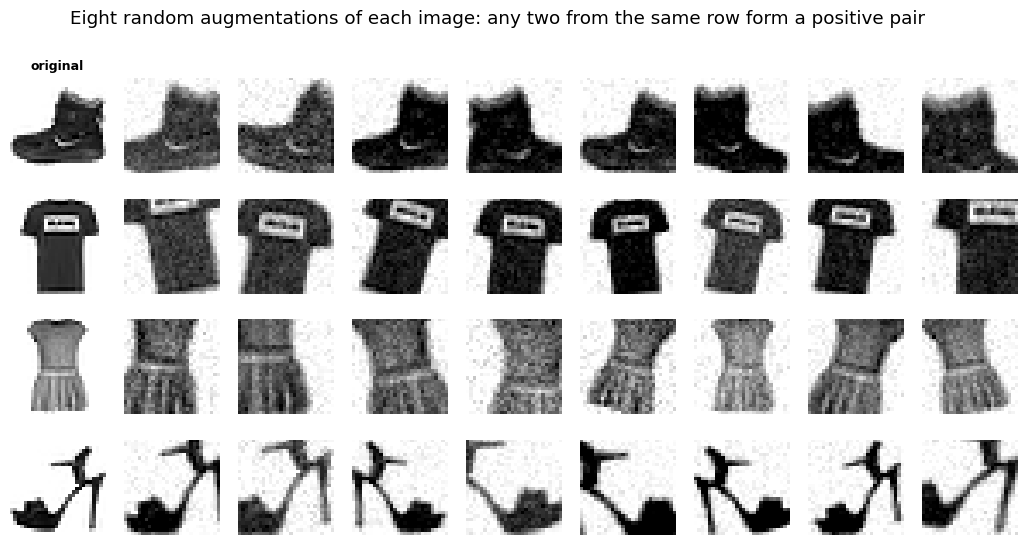

In [3]:
def augment(x):
    n = len(x)
    scale = torch.empty(n).uniform_(0.6, 1.0); angle = torch.empty(n).uniform_(-0.3, 0.3)           # zoom (crop) and rotate ±17°
    tx, ty = torch.empty(n).uniform_(-1, 1) * (1 - scale), torch.empty(n).uniform_(-1, 1) * (1 - scale)  # where to crop
    flip = torch.where(torch.rand(n) < 0.5, -1.0, 1.0)
    theta = torch.zeros(n, 2, 3)
    theta[:, 0, 0] = scale * torch.cos(angle) * flip; theta[:, 0, 1] = -scale * torch.sin(angle)
    theta[:, 1, 0] = scale * torch.sin(angle) * flip; theta[:, 1, 1] = scale * torch.cos(angle)
    theta[:, 0, 2], theta[:, 1, 2] = tx, ty
    x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), align_corners=False)
    x = x * torch.empty(n, 1, 1, 1).uniform_(0.6, 1.4)                                                 # contrast
    return (x + 0.05 * torch.randn_like(x)).clamp(0, 1)                                               # noise

torch.manual_seed(2)
fig, axes = plt.subplots(4, 9, figsize=(13, 6))
for r, i in enumerate([0, 1, 3, 9]):
    axes[r, 0].imshow(U[i, 0], cmap="gray_r"); axes[r, 0].set_title("original" if r == 0 else "", fontsize=9)
    views = augment(U[i:i + 1].repeat(8, 1, 1, 1))
    for k in range(8): axes[r, k + 1].imshow(views[k, 0], cmap="gray_r")
    for a in axes[r]: a.axis("off")
fig.suptitle("Eight random augmentations of each image: any two from the same row form a positive pair", y=0.99); plt.show()

Every row is still recognizably the same item. The network will be trained to map all of them to nearby points, and to keep them away from other rows.

---
## 4. The contrastive loss as multiclass classification

Take a batch of $N$ images, augment each one twice: $2N$ views. Pass all of them through the encoder $f$ and a small **projection head** $g$ (a 2-layer MLP) to get vectors $z_1, \dots, z_{2N}$, normalized to unit length. For each view $i$, exactly one of the other $2N - 1$ views is its positive partner $j(i)$; the rest are negatives. The loss treats "which one is my partner?" as a **$(2N-1)$-way classification** with cosine similarities as logits (CX lecture 21: *"SimCLR: multiclass classification"*):

$$\ell_i = -\log\frac{\exp\big(\mathrm{sim}(z_i, z_{j(i)})/\tau\big)}{\sum_{k\ne i}\exp\big(\mathrm{sim}(z_i, z_k)/\tau\big)}, \qquad \mathrm{sim}(u, v) = \frac{u^\top v}{\|u\|\|v\|}, \qquad \mathcal{L} = \frac{1}{2N}\sum_{i=1}^{2N}\ell_i.$$

This is exactly softmax regression's cross-entropy (notebook 08), where the "classes" are the other images in the batch. It's called **NT-Xent** (normalized temperature-scaled cross-entropy), a form of the **InfoNCE** loss. Minimizing it pulls positive pairs together (numerator) and pushes all other pairs apart (denominator). In code it's literally `cross_entropy` on a similarity matrix:

In [4]:
def nt_xent(z, tau=0.5):
    """z: (2N, d) projections, where rows i and i+N are the two views of image i."""
    z = F.normalize(z, dim=1); n = len(z) // 2
    sim = z @ z.T / tau                                        # all pairwise cosine similarities, scaled
    sim.fill_diagonal_(float("-inf"))                          # a view can't pick itself
    targets = torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)])   # view i's partner is i+N (and vice versa)
    return F.cross_entropy(sim, targets)

# Sanity checks on random vectors: perfectly matched pairs vs random pairs
torch.manual_seed(0); a = torch.randn(64, 32)
print(f"loss when each pair is identical:   {nt_xent(torch.cat([a, a])):.3f}")
print(f"loss when pairs are unrelated:      {nt_xent(torch.randn(128, 32)):.3f}   (≈ log(2N − 1) = {np.log(127):.3f} for random guessing)")
print(f"lowest possible loss at τ = 0.5 (partner at similarity 1, all 126 negatives at −1): {np.log(1 + 126 * np.exp(-4)):.3f}")

loss when each pair is identical:   2.940
loss when pairs are unrelated:      4.930   (≈ log(2N − 1) = 4.844 for random guessing)
lowest possible loss at τ = 0.5 (partner at similarity 1, all 126 negatives at −1): 1.196


Unrelated pairs give about $\log(2N - 1)$, the cross-entropy of guessing uniformly among the $2N - 1$ candidates. Identical pairs give a much lower value, but not zero: at τ = 0.5 the logits are capped at ±2, so the softmax can never be fully certain (the floor is printed on the last line), and random 32-D vectors are also somewhat similar to some negatives.

> 🤔 **Question: Why not just make the two views' features equal? Why do we need negatives at all?**
>
> Because the trivial solution "map every image to the same vector" makes every pair equal and learns nothing: **collapse**. The negatives in the denominator rule it out: to score well, the representation must also keep *different* images apart. That's the "contrastive" part. (Later methods such as BYOL and SimSiam avoid explicit negatives with architectural tricks, a momentum-averaged "teacher" network and a stop-gradient, which also prevent collapse.)

---
## 5. Temperature

The temperature $\tau$ controls how sharply the softmax focuses on the hardest negatives (the ones most similar to the anchor). 🎚️ **Move τ** and watch how the loss weights the negatives for one anchor, given a fixed set of similarities:

In [5]:
r_ = np.random.default_rng(0)
sims_neg = np.sort(np.clip(r_.normal(0.1, 0.25, 30), -1, 0.95))[::-1]; sim_pos = 0.7
def temperature_demo(tau=0.5):
    logits = np.r_[sim_pos, sims_neg] / tau; p = np.exp(logits - logits.max()); p /= p.sum()
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.bar(0, p[0], color=C["green"], label=f"positive (cos sim {sim_pos})")
    ax.bar(range(1, 31), p[1:], color=C["red"], label="negatives, most similar first")
    ax.set(xlabel="candidate", ylabel="softmax probability", ylim=(0, 1),
           title=f"τ = {tau:.2f}: loss for this anchor = −log p(positive) = {-np.log(p[0]):.2f};  top negative gets {p[1] / p[1:].sum():.0%} of the negatives' weight")
    ax.legend(); plt.show()

interact(temperature_demo, tau=FloatSlider(value=0.5, min=0.05, max=2.0, step=0.05, description="τ"));

Small τ makes the softmax sharp: the loss is dominated by the few negatives most similar to the anchor, so training focuses on fine distinctions (shirt vs. T-shirt), but it can also over-penalize near-duplicates that are genuinely the same kind of thing. Large τ spreads attention over all negatives evenly, which gives a weaker training signal. Values around 0.1–0.5 are typical.

---
## 6. SimCLR from scratch

The full training loop: augment each batch twice, encode, project, NT-Xent, backprop. **No labels are used.** Following the paper, the projection head is used only for the loss; afterwards we keep the encoder's 128-D output (the layer *before* the head), which works better for downstream tasks because the head learns to discard information (like color or orientation) that the augmentations made irrelevant to the pretext task but might still be useful later.

In [6]:
EPOCHS = 6                                 # ~4 minutes on a CPU; more epochs (and data) keep improving the representation
torch.manual_seed(0)
encoder = Encoder().to(device)
head = nn.Sequential(nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 64)).to(device)
opt = torch.optim.Adam(list(encoder.parameters()) + list(head.parameters()), lr=1e-3)
losses, t0 = [], time.time()
for ep in range(EPOCHS):
    encoder.train(); head.train(); ep_loss = []
    for idx in torch.randperm(len(U)).split(256):
        x = U[idx]
        views = torch.cat([augment(x), augment(x)]).to(device)     # 2N views; rows i and i+N are partners
        loss = nt_xent(head(encoder(views)))
        opt.zero_grad(); loss.backward(); opt.step(); ep_loss.append(loss.item())
    losses.append(np.mean(ep_loss)); print(f"epoch {ep + 1}: contrastive loss {losses[-1]:.3f}  ({time.time() - t0:.0f}s)")
print(f"(random guessing among 2N − 1 = 511 candidates would give log 511 = {np.log(511):.2f})")

epoch 1: contrastive loss 4.939  (34s)


epoch 2: contrastive loss 4.716  (68s)


epoch 3: contrastive loss 4.660  (101s)


epoch 4: contrastive loss 4.626  (135s)


epoch 5: contrastive loss 4.604  (170s)


epoch 6: contrastive loss 4.588  (203s)
(random guessing among 2N − 1 = 511 candidates would give log 511 = 6.24)


The loss falls steadily: the network is learning to pick out each image's partner from a crowd of 510 other views. Keep the scale in mind when reading these numbers. Uniform guessing among 511 candidates would give $\log 511 \approx 6.2$, and because cosine similarities live in $[-1, 1]$ and we divide by $\tau = 0.5$, the logits can only range from −2 to +2, so even a perfect representation (partner at similarity 1, every negative at −1) can't push the loss below $\log(1 + 510e^{-4}) \approx 2.3$. A loss of about 4.6 after six short epochs means the partner is ranked highly but far from certain, and the representation would keep improving with more training.

---
## 7. Linear probes with few labels

Now the real test. Freeze the encoder, and train only a logistic regression on top using 100, 1,000, or 5,000 **labeled** images. We evaluate on the test set as is, and also on a version where every test image is randomly **shifted, rotated, and rescaled** a little, the kind of variation real photos have and Fashion-MNIST's carefully centered images don't:

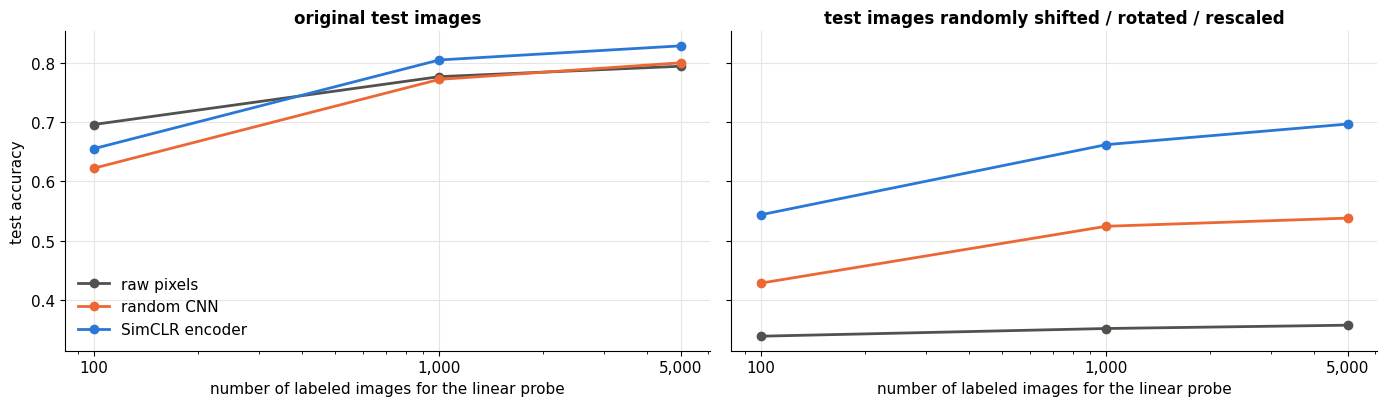

clean_test                        jittered_test             \
representation SimCLR encoder random CNN raw pixels SimCLR encoder random CNN   
labels                                                                          
100                     0.655      0.622      0.696          0.544      0.428   
1000                    0.805      0.772      0.777          0.662      0.524   
5000                    0.829      0.800      0.794          0.697      0.538   

                           
representation raw pixels  
labels                     
100                 0.339  
1000                0.352  
5000                0.357

In [7]:
def jitter(x, seed=1):
    g = torch.Generator().manual_seed(seed); n = len(x)
    ang = torch.empty(n).uniform_(-0.35, 0.35, generator=g); s = torch.empty(n).uniform_(0.8, 1.1, generator=g)
    tx, ty = torch.empty(n).uniform_(-0.25, 0.25, generator=g), torch.empty(n).uniform_(-0.25, 0.25, generator=g)
    th = torch.zeros(n, 2, 3); th[:, 0, 0] = s * torch.cos(ang); th[:, 0, 1] = -s * torch.sin(ang); th[:, 1, 0] = s * torch.sin(ang); th[:, 1, 1] = s * torch.cos(ang)
    th[:, 0, 2], th[:, 1, 2] = tx, ty
    return F.grid_sample(x, F.affine_grid(th, x.shape, align_corners=False), align_corners=False)
XT_jit = jitter(XT)

rows = []
F_simclr_test, F_simclr_jit = features(encoder, XT), features(encoder, XT_jit)
F_rand_test, F_rand_jit = features(random_enc, XT), features(random_enc, XT_jit)
for n_lab in [100, 1000, 5000]:
    sets = {"raw pixels": (U[:n_lab].flatten(1).numpy(), XT.flatten(1).numpy(), XT_jit.flatten(1).numpy()),
            "random CNN": (features(random_enc, U[:n_lab]), F_rand_test, F_rand_jit),
            "SimCLR encoder": (features(encoder, U[:n_lab]), F_simclr_test, F_simclr_jit)}
    for name, (Ftr, Fte, Fj) in sets.items():
        sc = StandardScaler().fit(Ftr); clf = LogisticRegression(max_iter=3000).fit(sc.transform(Ftr), y_U[:n_lab])
        rows.append(dict(labels=n_lab, representation=name, clean_test=clf.score(sc.transform(Fte), YT), jittered_test=clf.score(sc.transform(Fj), YT)))
res = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, col, title in [(axes[0], "clean_test", "original test images"), (axes[1], "jittered_test", "test images randomly shifted / rotated / rescaled")]:
    for name, c in zip(["raw pixels", "random CNN", "SimCLR encoder"], [C["muted"], C["orange"], C["blue"]]):
        d = res[res.representation == name]; ax.plot(d.labels, d[col], "o-", color=c, lw=2, label=name)
    ax.set(xscale="log", xticks=[100, 1000, 5000], xticklabels=["100", "1,000", "5,000"], xlabel="number of labeled images for the linear probe", title=title)
axes[0].set_ylabel("test accuracy"); axes[0].legend()
fig.tight_layout(); plt.show()
res.pivot(index="labels", columns="representation", values=["clean_test", "jittered_test"]).round(3)

Two findings, one modest and one striking:

- **On the clean test set**, the SimCLR features beat pixels and random features once there are 1,000 or more labels, by about 3 points. With only 100 labels, raw pixels are still competitive here: Fashion-MNIST images are centered, aligned, and simple, so pixels are a decent representation already, and six CPU epochs of contrastive training is a very short run. (In the SimCLR paper, much longer training on large images gives representations whose linear probes rival fully supervised networks.)
- **On jittered test images**, the difference is dramatic. A linear model on pixels collapses to about 35% accuracy, because a shifted shirt activates entirely different pixels. The random CNN degrades less (around 50%), thanks to convolution and pooling. The SimCLR representation holds up far better, because it was **trained to be invariant** to exactly these transformations: two crops of the same shirt had to map to the same point.

That's the essence of contrastive learning: **the augmentations define the invariances, and the representation inherits them.** Choosing augmentations is choosing what "the same" means.

---
## 8. What the embedding learned

Two views of the learned space. First, **nearest neighbors**: for a few query images, find the closest test images by cosine similarity of their SimCLR features. No labels were used to build this similarity:

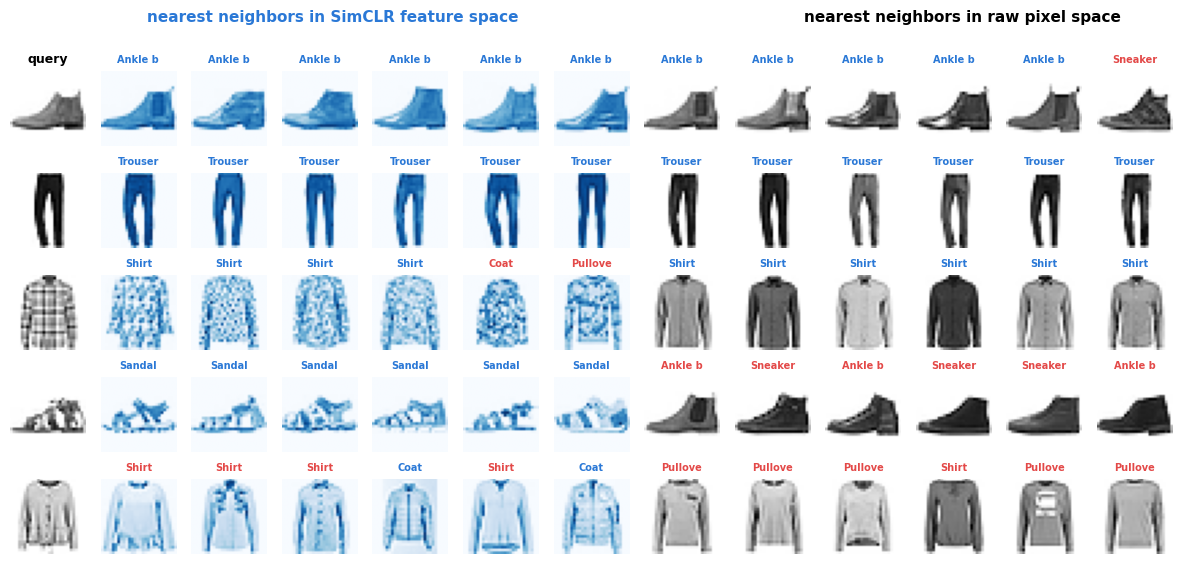

1-nearest-neighbor accuracy, clean queries,    SimCLR features: 75.3%


1-nearest-neighbor accuracy, clean queries,    raw pixels     : 79.5%


1-nearest-neighbor accuracy, jittered queries, SimCLR features: 66.7%


1-nearest-neighbor accuracy, jittered queries, raw pixels     : 45.0%


In [8]:
Fn = F_simclr_test / np.linalg.norm(F_simclr_test, axis=1, keepdims=True)
Pn = XT.flatten(1).numpy(); Pn = Pn / np.linalg.norm(Pn, axis=1, keepdims=True)
queries = [0, 2, 7, 11, 25]
fig, axes = plt.subplots(len(queries), 13, figsize=(15, 6.4))
for r, q in enumerate(queries):
    nn_feat = np.argsort(-(Fn @ Fn[q]))[1:7]; nn_pix = np.argsort(-(Pn @ Pn[q]))[1:7]
    axes[r, 0].imshow(XT[q, 0], cmap="gray_r"); axes[r, 0].set_title("query" if r == 0 else "", fontsize=9)
    for k, i in enumerate(nn_feat):
        axes[r, 1 + k].imshow(XT[i, 0], cmap="Blues"); axes[r, 1 + k].set_title(CLASSES[YT[i]][:7], fontsize=7, color=C["blue"] if YT[i] == YT[q] else C["red"])
    for k, i in enumerate(nn_pix):
        axes[r, 7 + k].imshow(XT[i, 0], cmap="Greys"); axes[r, 7 + k].set_title(CLASSES[YT[i]][:7], fontsize=7, color=C["blue"] if YT[i] == YT[q] else C["red"])
    for a in axes[r]: a.axis("off")
fig.text(0.34, 0.95, "nearest neighbors in SimCLR feature space", ha="center", color=C["blue"], weight="bold")
fig.text(0.76, 0.95, "nearest neighbors in raw pixel space", ha="center", weight="bold")
plt.show()
for nm, M in [("SimCLR features", Fn), ("raw pixels", Pn)]:
    nn1 = np.argsort(-(M @ M.T), axis=1)[:, 1]; print(f"1-nearest-neighbor accuracy, clean queries,    {nm:15s}: {np.mean(YT[nn1] == YT):.1%}")
Fj = F_simclr_jit / np.linalg.norm(F_simclr_jit, axis=1, keepdims=True); Pj = XT_jit.flatten(1).numpy(); Pj = Pj / np.linalg.norm(Pj, axis=1, keepdims=True)
for nm, Q, M in [("SimCLR features", Fj, Fn), ("raw pixels", Pj, Pn)]:
    nn1 = np.argsort(-(Q @ M.T), axis=1)[:, 0]; print(f"1-nearest-neighbor accuracy, jittered queries, {nm:15s}: {np.mean(YT[nn1] == YT):.1%}")

Both find mostly same-class neighbors (label colors: blue = same class as the query, red = different), and on these clean, centered images plain pixel similarity is actually a little *more* accurate for 1-nearest-neighbor matching: identical-looking photos are close in pixel space, and our short training run hasn't made the features finer-grained than that. The printout's second half tells the other story: when the query is a jittered image, pixel matching falls apart while feature matching degrades much less. This kind of label-free similarity search is exactly how image search, deduplication, and "more like this" recommendation work in practice.

Second, a **map** of the representation (its first two principal components), colored by the labels that training never saw:

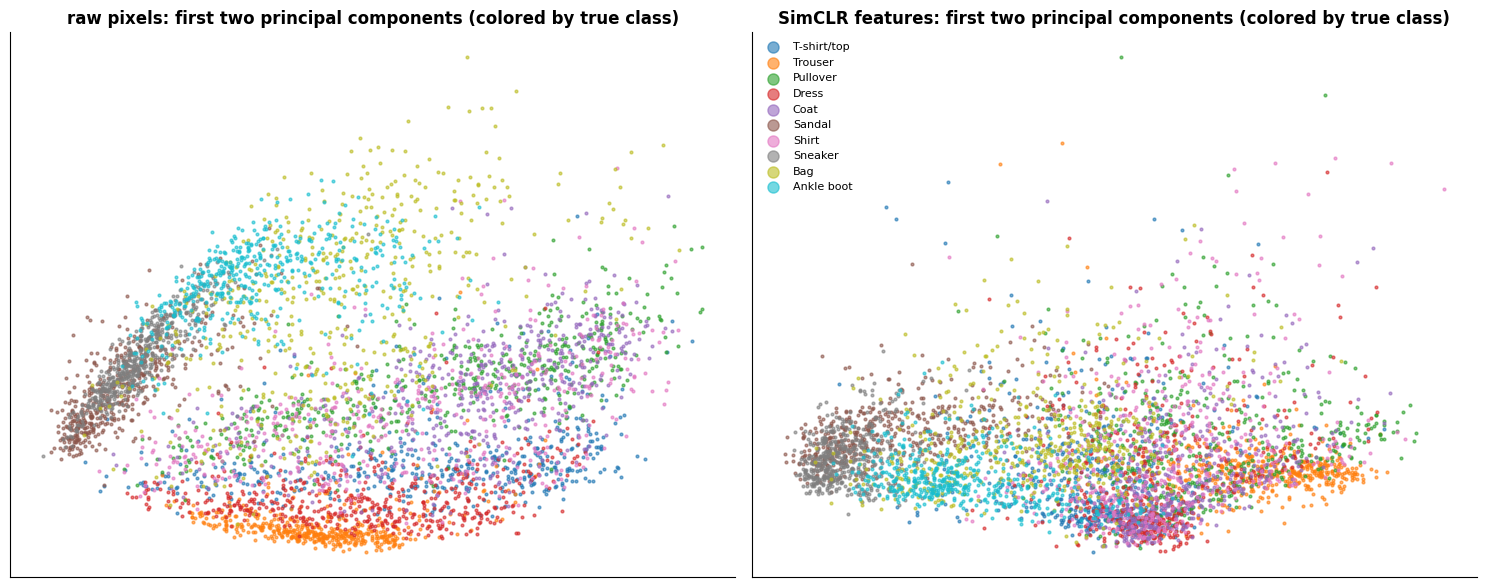

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cmap10 = plt.get_cmap("tab10")
for ax, (Fx, nm) in zip(axes, [(XT.flatten(1).numpy(), "raw pixels"), (F_simclr_test, "SimCLR features")]):
    Z = PCA(2).fit_transform(StandardScaler().fit_transform(Fx))
    for c in range(10): ax.scatter(*Z[YT == c].T, s=4, color=cmap10(c), label=CLASSES[c], alpha=0.6)
    ax.set(title=f"{nm}: first two principal components (colored by true class)", xticks=[], yticks=[])
axes[1].legend(markerscale=4, fontsize=8, loc="best"); fig.tight_layout(); plt.show()

A caution about pictures like this: neither map looks cleanly separated, and the SimCLR map doesn't look *better* than the pixel one even though its linear probe is more accurate. Two principal components capture only a sliver of a 128-dimensional representation, and contrastive features tend to spread information evenly across many directions (that's what pushing all negatives apart encourages), so no 2-D linear view shows much. The quantitative tests (probe accuracy, nearest-neighbor accuracy under jitter) are the evidence; a nonlinear map such as t-SNE or UMAP (exercise) gives a more faithful picture of neighborhoods.

---
## 9. Beyond SimCLR

The same recipe, *pairs that should match, contrasted against pairs that shouldn't*, powers much of modern AI (CX lecture 21's "extensions"):

| Method | Positive pair | What it learns |
|---|---|---|
| **word2vec** (2013) | a word and a word in its context window | word embeddings where similar words are close |
| **CPC** (2018) | a sequence's past and its future | representations of audio, text, images by predicting what comes next |
| **SimCLR** (2020) | two augmentations of one image | invariant image features (needs big batches for many negatives) |
| **MoCo** (2020) | same, with a queue of past negatives and a momentum encoder | SimCLR's idea without huge batches |
| **BYOL / SimSiam / DINO** | same, **no negatives** (teacher–student with stop-gradient) | avoids collapse by asymmetry instead of negatives |
| **CLIP** (2021) | an image and its caption | a shared image–text space: zero-shot classification by comparing an image with the text "a photo of a {class}" |

CLIP is the clearest descendant: 400 million image–caption pairs from the web, a batch-level softmax exactly like our NT-Xent between image and text embeddings, and the result became the "eyes" of many generative image systems. Text **embedding models**, used for semantic search and retrieval-augmented generation with LLMs, are trained the same way: a query and a relevant passage as the positive pair, other passages in the batch as negatives.

---
## 10. Summary

- **Representation learning** turns unlabeled data into features that make later tasks easy. Measure it with a **linear probe**: frozen features + logistic regression on a few labels.
- **Contrastive learning** synthesizes labels from the data itself: two augmented **views** of one image are a positive pair; views of other images are negatives.
- The **NT-Xent / InfoNCE** loss is softmax cross-entropy over cosine similarities: "pick your partner out of the batch". Negatives prevent **collapse**; the **temperature** sets how hard the negatives are weighted.
- **The augmentations define the invariances**: our SimCLR encoder kept its accuracy on shifted, rotated, rescaled images far better than pixels, because it was trained to ignore exactly those changes.
- The idea scales from word2vec to CLIP and to the embedding models used with LLMs, which is where Part 5 picks up.

### ✏️ Exercises

1. Show that NT-Xent with one negative reduces to logistic regression on the difference of similarities (CX lecture 21's binary-classification view).
2. Train SimCLR with **only** the crop-and-resize augmentation, then with only flips and contrast. Compare clean and jittered linear-probe accuracy. Which augmentation matters most?
3. Vary the batch size (64, 256, 512) at a fixed number of epochs. How does the probe accuracy change, and why do more negatives help?
4. Use the projection head's output $g(f(x))$ instead of $f(x)$ for the linear probe. Is it better or worse? Why might the head discard useful information?
5. Compare with the VAE from notebook 23: train a linear probe on its encoder means $\mu_\phi(x)$ (16-D) on the same clean and jittered test sets.
6. Train for 30 epochs (on a GPU runtime, with `N_UNLABELED = 60000`) and plot probe accuracy against epochs. When does it stop improving?
7. Make a t-SNE map (`sklearn.manifold.TSNE`) of the SimCLR features and of the raw pixels, colored by class. How does it compare with the PCA map?

### References

- CX 4240 lecture 21 (Representation Learning).
- T. Chen, S. Kornblith, M. Norouzi & G. Hinton, *A Simple Framework for Contrastive Learning of Visual Representations* (SimCLR), ICML (2020).
- A. van den Oord, Y. Li & O. Vinyals, *Representation Learning with Contrastive Predictive Coding* (2018) (InfoNCE).
- K. He et al., *Momentum Contrast for Unsupervised Visual Representation Learning* (MoCo), CVPR (2020); J.-B. Grill et al., *Bootstrap Your Own Latent* (BYOL), NeurIPS (2020).
- A. Radford et al., *Learning Transferable Visual Models From Natural Language Supervision* (CLIP), ICML (2021).
- T. Mikolov et al., *Distributed Representations of Words and Phrases and their Compositionality* (word2vec), NeurIPS (2013).
- T. Wang & P. Isola, *Understanding Contrastive Representation Learning through Alignment and Uniformity on the Hypersphere*, ICML (2020).

**Next → [25 · Attention & a Mini-GPT](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/25_attention_mini_gpt.ipynb)**